# Projeto e Simulação de Conversor CC-CC Buck em Malha Aberta

## 1. Topologia e Nomenclatura
Este projeto baseia-se na seguinte topologia clássica do regulador abaixador (*Buck*)

![buck](topologia_buck.png)

### Nomenclatura Adotada (conforme diagrama):
* **$V_s$**: Tensão contínua de entrada (Fonte CC).
* **$i_s, I_s$**: Corrente instantânea e corrente média de entrada.
* **$Q_1$**: Chave semicondutora controlada (Transistor de potência).
* **$D_m$**: Diodo de roda livre (*freewheeling diode*).
* **$L$**: Indutor de filtro; **$e_L$**: Tensão sobre o indutor; **$i_L, I_L$**: Corrente instantânea e média no indutor.
* **$C$**: Capacitor de filtro; **$v_c$**: Tensão no capacitor; **$i_c, I_c$**: Corrente instantânea e média no capacitor.
* **$R$**: Resistência de carga.
* **$v_o, V_a$**: Tensão instantânea e tensão média na saída (carga).
* **$i_o, I_a$**: Corrente instantânea e corrente média na carga.
* **$k$**: Ciclo de trabalho (*duty cycle* / razão cíclica), definido por $k = t_1 / T$.
* **$f, T$**: Frequência e período de chaveamento ($T = 1/f$).

---

## 2. Equacionamento de Projeto (Modo de Condução Contínua - MCC)

1. **Relação de Tensão e Ciclo de Trabalho ($k$):**
   $$V_a = k \cdot V_s \implies k = \frac{V_a}{V_s}$$

2. **Ondulação de Corrente no Indutor ($\Delta I$) e Indutância de Filtro ($L$):**
   $$\Delta I = \frac{V_a(V_s - V_a)}{f \cdot L \cdot V_s} = \frac{V_s \cdot k(1 - k)}{f \cdot L} \implies L = \frac{V_a(V_s - V_a)}{\Delta I \cdot f \cdot V_s}$$

3. **Ondulação de Tensão no Capacitor ($\Delta V_c$) e Capacitância de Filtro ($C$):**
   $$\Delta V_c = \frac{\Delta I}{8 \cdot f \cdot C} = \frac{V_s \cdot k(1 - k)}{8 \cdot L \cdot C \cdot f^2} \implies C = \frac{\Delta I}{8 \cdot f \cdot \Delta V_c}$$

4. **Valores Críticos de Indutância ($L_c$) e Capacitância ($C_c$):**
   Limites fronteiriços entre o Modo de Condução Contínua (MCC) e Descontínua (MCD):
   $$L_c = \frac{(1 - k)R}{2f} \quad \text{e} \quad C_c = \frac{1 - k}{16 \cdot L \cdot f^2}$$


---


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==============================================================================
# 1. ESPECIFICAÇÕES DE PROJETO
# ==============================================================================
Vs = 12.0          # Tensão de entrada [V]
Va = 5.0           # Tensão média de saída desejada [V]
R = 5.0            # Resistência de carga nominal [Ohms]
delta_Vc = 20e-3   # Ondulação máxima de tensão no capacitor (20 mV) [V]
delta_I = 0.3      # Ondulação máxima de corrente no indutor (30% de Ia) [A]
f = 25e3           # Frequência de chaveamento (25 kHz) [Hz]
T = 1.0 / f        # Período de chaveamento [s]

# ==============================================================================
# 2. CÁLCULOS DE PROJETO
# ==============================================================================
# (a) Ciclo de trabalho (k)
k = Va / Vs

# (b) Indutância do filtro (L)
L = (Va * (Vs - Va)) / (delta_I * f * Vs)

# (c) Capacitância do filtro (C)
C = delta_I / (8 * f * delta_Vc)

# (d) Valores críticos (Lc e Cc)
Lc = ((1 - k) * R) / (2 * f)
Cc = (1 - k) / (16 * L * (f ** 2))

# Corrente média de carga nominal
Ia = Va / R

print("=== RESULTADOS DO DIMENSIONAMENTO ===")
print(f"(a) Ciclo de trabalho (k)     : {k:.4f} ({k*100:.2f} %)")
print(f"(b) Indutância de filtro (L)  : {L*1e6:.2f} uH")
print(f"(c) Capacitância de filtro (C): {C*1e6:.2f} uF")
print(f"(d) Indutância crítica (Lc)   : {Lc*1e6:.2f} uH")
print(f"    Capacitância crítica (Cc) : {Cc*1e6:.2f} uF")
print("-" * 51)
print(f"Corrente média na carga (Ia)  : {Ia:.2f} A ({Ia*1e3:.1f} mA)")
print(f"Modo de operação              : {'MCC (L > Lc)' if L > Lc else 'MCD (L < Lc)'}")

=== RESULTADOS DO DIMENSIONAMENTO ===
(a) Ciclo de trabalho (k)     : 0.4167 (41.67 %)
(b) Indutância de filtro (L)  : 388.89 uH
(c) Capacitância de filtro (C): 75.00 uF
(d) Indutância crítica (Lc)   : 58.33 uH
    Capacitância crítica (Cc) : 0.15 uF
---------------------------------------------------
Corrente média na carga (Ia)  : 1.00 A (1000.0 mA)
Modo de operação              : MCC (L > Lc)


## 3. Modelo Matemático para Análise Dinâmica (Espaço de Estados Médio)

Para avaliar o comportamento dinâmico da tensão de saída ($v_o = v_c$) frente a **degraus de razão cíclica ($\Delta k$)** e **degraus de carga ($\Delta R$ ou $\Delta i_o$)** em malha aberta, utilizamos o modelo médio no espaço de estados operando em MCC:

### Equações Diferenciais Médias:
Durante o Modo 1 ($0 < t \le kT$), $Q_1$ conduz e $e_L = V_s - v_c$. Durante o Modo 2 ($kT < t \le T$), $D_m$ conduz e $e_L = -v_c$. Pela média em um período de chaveamento $T$:

$$\begin{cases}
L \frac{di_L(t)}{dt} = k(t) \cdot V_s - v_c(t) \\[6pt]
C \frac{dv_c(t)}{dt} = i_L(t) - i_o(t) = i_L(t) - \frac{v_c(t)}{R(t)}
\end{cases}$$

### Funções de Transferência em Malha Aberta (Domínio $s$):
Aplicando a Transformada de Laplace para pequenas perturbações em torno do ponto de operação:

1. **Função de Transferência Controle-Saída $G_{vk}(s)$ (sem variação externa de carga, $\hat{R} = 0$):**
   $$G_{vk}(s) = \frac{\hat{v}_o(s)}{\hat{k}(s)} = \frac{V_s}{L C s^2 + \frac{L}{R}s + 1} = \frac{V_s / (LC)}{s^2 + \frac{1}{RC}s + \frac{1}{LC}}$$

2. **Impedância de Saída $Z_{out}(s)$ (resposta a uma perturbação externa de corrente $\hat{i}_{o,\text{ext}}$ drenada da saída, com $\hat{k} = 0$):**
   $$Z_{out}(s) = -\frac{\hat{v}_o(s)}{\hat{i}_{o,\text{ext}}(s)} = \frac{\frac{s}{C}}{s^2 + \frac{1}{RC}s + \frac{1}{LC}}$$

Onde a frequência natural não amortecida ($\omega_0$) e o fator de amortecimento ($\zeta$) do filtro $LC$ são:
$$\omega_0 = \frac{1}{\sqrt{LC}} \quad \text{e} \quad \zeta = \frac{1}{2R}\sqrt{\frac{L}{C}}$$


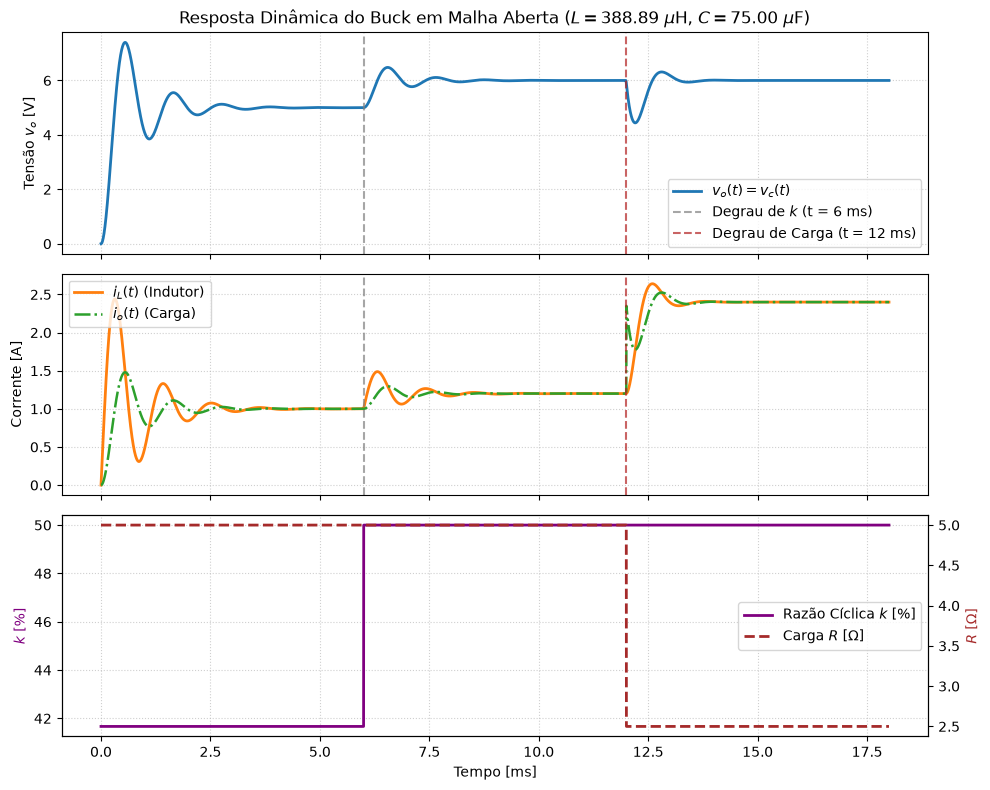

In [21]:
# ==============================================================================
# 3. SIMULAÇÃO DINÂMICA (RESPOSTA A DEGRAUS DE RAZÃO CÍCLICA E DE CARGA)
# ==============================================================================
# Perfis temporais:
# - t =  0.0 ms: Partida do repouso (i_L = 0, v_c = 0) com k = 41.67% e R = 5.0 Ohms
# - t =  6.0 ms: Degrau na razão cíclica k (41.67% -> 50.0% => Va esperado = 6.0 V)
# - t = 12.0 ms: Degrau de carga (R cai de 5.0 Ohms para 2.5 Ohms => dobra corrente)

t_degrau_k = 6.0e-3
t_degrau_R = 12.0e-3
k_novo = 0.50
R_novo = 2.5

def k_profile(t):
    """Retorna a razão cíclica k(t) em função do tempo."""
    return k if t < t_degrau_k else k_novo

def R_profile(t):
    """Retorna a resistência de carga R(t) em função do tempo."""
    return R if t < t_degrau_R else R_novo

def buck_ode(t, x):
    """
    Sistema de EDOs do conversor Buck médio:
    x[0] = i_L (Corrente média no indutor)
    x[1] = v_c (Tensão média no capacitor = v_o)
    """
    i_L, v_c = x
    kt = k_profile(t)
    Rt = R_profile(t)
    
    i_o = v_c / Rt
    diL_dt = (kt * Vs - v_c) / L
    dvc_dt = (i_L - i_o) / C
    return [diL_dt, dvc_dt]

# Condições iniciais (circuito desenergizado em t = 0)
x0 = [0.0, 0.0]
t_span = (0.0, 18e-3)
t_eval = np.linspace(t_span[0], t_span[1], 6000)

# Resolução numérica com max_step=T para capturar exatamente os instantes dos degraus
sol = solve_ivp(buck_ode, t_span, x0, t_eval=t_eval, method='RK45', max_step=T)

# Extração das variáveis
t_ms = sol.t * 1e3
i_L_sim = sol.y[0]
v_o_sim = sol.y[1]
k_sim = np.array([k_profile(ti) for ti in sol.t])
R_sim = np.array([R_profile(ti) for ti in sol.t])
i_o_sim = v_o_sim / R_sim

# ==============================================================================
# 4. PLOTAGEM DOS RESULTADOS
# ==============================================================================
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Gráfico 1: Tensão de Saída (v_o)
axs[0].plot(t_ms, v_o_sim, color='#1f77b4', lw=2, label=r'$v_o(t) = v_c(t)$')
axs[0].axvline(t_degrau_k * 1e3, color='gray', linestyle='--', alpha=0.7, label=f'Degrau de $k$ (t = {t_degrau_k*1e3:.0f} ms)')
axs[0].axvline(t_degrau_R * 1e3, color='firebrick', linestyle='--', alpha=0.7, label=f'Degrau de Carga (t = {t_degrau_R*1e3:.0f} ms)')
axs[0].set_ylabel('Tensão $v_o$ [V]')
axs[0].set_title(rf'Resposta Dinâmica do Buck em Malha Aberta ($L = {L*1e6:.2f}\ \mu\mathrm{{H}}$, $C = {C*1e6:.2f}\ \mu\mathrm{{F}}$)')
axs[0].grid(True, linestyle=':', alpha=0.6)
axs[0].legend(loc='lower right')

# Gráfico 2: Corrente no Indutor (i_L) e Corrente de Carga (i_o)
axs[1].plot(t_ms, i_L_sim, color='#ff7f0e', lw=2, label=r'$i_L(t)$ (Indutor)')
axs[1].plot(t_ms, i_o_sim, color='#2ca02c', lw=1.8, linestyle='-.', label=r'$i_o(t)$ (Carga)')
axs[1].axvline(t_degrau_k * 1e3, color='gray', linestyle='--', alpha=0.7)
axs[1].axvline(t_degrau_R * 1e3, color='firebrick', linestyle='--', alpha=0.7)
axs[1].set_ylabel('Corrente [A]')
axs[1].grid(True, linestyle=':', alpha=0.6)
axs[1].legend(loc='upper left')

# Gráfico 3: Entradas de Estímulo (Razão Cíclica k e Carga R)
ax3_twin = axs[2].twinx()
p1, = axs[2].plot(t_ms, k_sim * 100, color='purple', lw=2, label='Razão Cíclica $k$ [%]')
p2, = ax3_twin.plot(t_ms, R_sim, color='brown', lw=2, linestyle='--', label=r'Carga $R$ [$\Omega$]')
axs[2].set_ylabel('$k$ [%]', color='purple')
ax3_twin.set_ylabel(r'$R$ [$\Omega$]', color='brown')
axs[2].set_xlabel('Tempo [ms]')
axs[2].grid(True, linestyle=':', alpha=0.6)
axs[2].legend(handles=[p1, p2], loc='center right')

plt.tight_layout()
plt.show()

Na simulação dinamica acima temos o resultado da simulação do buck com degrau de razão cíclica e logo após um degrau de carga